# 05 · Modeling — first batch

Target: `price` from the API, which may represent a listing or recent sale price. Use XGBoost without `status` or previous sale date as the candidate pipeline: its validation MAE was close to the context model and it avoids uncertain prediction-time inputs. Batch 0 contains only `for_sale` rows; validate the choice on later batches.


## Imports

In [1]:
import json
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sys.path.insert(0, str(Path('../src').resolve()))
from property_ml.features import build_model, prepare
from property_ml.splitting import assign_splits


## Load batch

In [2]:
DATA = Path('../data')
GROUP = int(os.environ['DATA_API_GROUP'])
files = sorted(DATA.glob(f'group-{GROUP}-*.json'))
if not files:
    raise FileNotFoundError('Collect a batch in notebook 01 first.')
with files[0].open() as file:
    batch = json.load(file)
df = pd.DataFrame(batch['data'])
print(f"Group {GROUP} | batch {batch['batch_number']} | {len(df):,} rows")


Group 4 | batch 0 | 73,784 rows


## Features and split

In [3]:
data = df.loc[df['price'].notna() & df['price'].gt(0)].copy()
data['total_rooms'] = data['bed'] + data['bath']
data['size_per_room'] = data['house_size'] / data['total_rooms'].where(data['total_rooms'] > 0)
data['previous_sale_year'] = pd.to_datetime(data['prev_sold_date'], errors='coerce').dt.year
numeric = ['bed', 'bath', 'acre_lot', 'house_size', 'total_rooms', 'size_per_room', 'previous_sale_year']
categorical = ['brokered_by', 'status', 'street', 'city', 'state', 'zip_code']
X = prepare(data)
X['previous_sale_year'] = data['previous_sale_year']
X['status'] = data['status'].astype('string').fillna('missing').astype(str)
y = data['price']
splits = assign_splits(data)
X_train, X_val, X_test = (X.loc[splits == name] for name in ['train', 'validation', 'test'])
y_train, y_val, y_test = (y.loc[splits == name] for name in ['train', 'validation', 'test'])
print('Train / validation / test:', len(X_train), len(X_val), len(X_test))


Train / validation / test: 44123 15014 14647


## Train and compare

In [4]:
def preprocessor(quadratic=False, engineered=True, include_context=True):
    selected_numeric = numeric if engineered else ['bed', 'bath', 'acre_lot', 'house_size', 'previous_sale_year']
    if not include_context:
        selected_numeric = [name for name in selected_numeric if name != 'previous_sale_year']
    selected_categorical = categorical if include_context else [name for name in categorical if name != 'status']
    numeric_steps = [('impute', SimpleImputer(strategy='median'))]
    if quadratic:
        numeric_steps.append(('squared', PolynomialFeatures(degree=2, interaction_only=False, include_bias=False)))
    numeric_steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), selected_numeric),
        ('categorical', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, max_categories=100), selected_categorical),
    ])
models = {
    'median baseline': DummyRegressor(strategy='median'),
    'ridge basic': Pipeline([('preprocess', preprocessor(engineered=False)), ('model', Ridge(solver='lsqr'))]),
    'ridge engineered': Pipeline([('preprocess', preprocessor()), ('model', Ridge(solver='lsqr'))]),
    'ridge quadratic': Pipeline([('preprocess', preprocessor(quadratic=True)), ('model', Ridge(solver='lsqr'))]),
    'random forest': Pipeline([('preprocess', preprocessor()), ('model', RandomForestRegressor(n_estimators=30, max_depth=12, min_samples_leaf=10, n_jobs=1, random_state=42))]),
    'xgboost without status/date': build_model(),
    'xgboost with status/date': Pipeline([('preprocess', preprocessor()), ('model', XGBRegressor(n_estimators=120, max_depth=5, learning_rate=.1, tree_method='hist', n_jobs=1, random_state=42))]),
}
def scores(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted), 'RMSE': mean_squared_error(actual, predicted) ** .5, 'R2': r2_score(actual, predicted)}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({'model': name, **scores(y_val, model.predict(X_val))})
    print(f'{name}: done')
results = pd.DataFrame(rows).sort_values('MAE')
display(results)


median baseline: done
ridge basic: done
ridge engineered: done
ridge quadratic: done
random forest: done
xgboost without status/date: done
xgboost with status/date: done


,model,MAE,RMSE,R2
6,xgboost with status/date,44041.061483,55072.791308,0.292750
5,xgboost without status/date,44278.238084,55336.893034,0.285951
4,random forest,45070.634383,56474.558870,0.256289
3,ridge quadratic,45532.228426,56997.119570,0.242462
2,ridge engineered,46321.509823,57620.831861,0.225792
1,ridge basic,46338.112953,57621.689127,0.225769
0,median baseline,52916.828160,67419.266676,-0.059904


## Test the selected model

In [5]:
best_name = 'xgboost without status/date'
prediction = models[best_name].predict(X_test)
print('Chosen candidate pipeline:', best_name)
display(pd.DataFrame([scores(y_test, prediction)], index=['test']))


Chosen candidate pipeline: xgboost without status/date


,MAE,RMSE,R2
test,44237.930849,55692.780959,0.266049


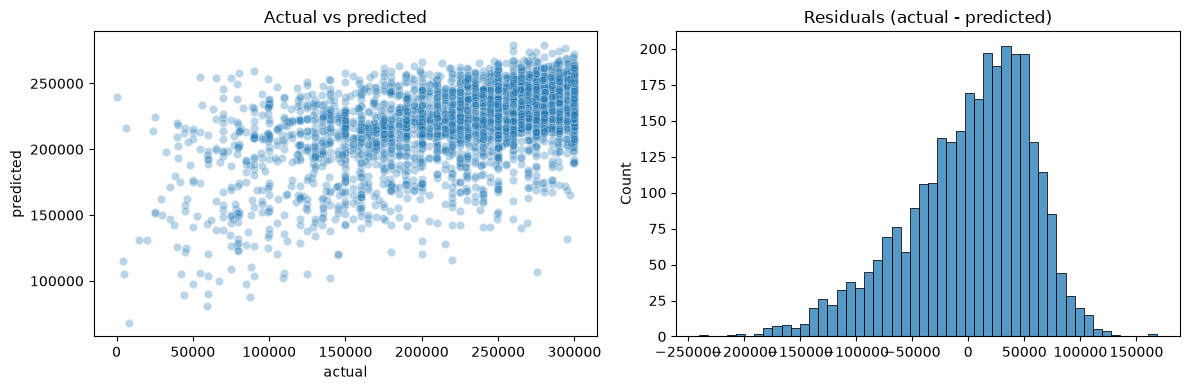

In [6]:
plot = pd.DataFrame({'actual': y_test, 'predicted': prediction}).sample(n=min(3000, len(y_test)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=plot, x='actual', y='predicted', alpha=.3, ax=axes[0])
axes[0].set_title('Actual vs predicted')
sns.histplot(plot['actual'] - plot['predicted'], bins=50, ax=axes[1])
axes[1].set_title('Residuals (actual - predicted)')
plt.tight_layout()
plt.show()
